In [2]:
import numpy as np
import netCDF4 as nc
import xarray as xr
import os
import json
from pathlib import Path
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.lines as mlines
from matplotlib.colors import TwoSlopeNorm
import pandas as pd
import cartopy.crs as ccrs
# from ladcp_tools import *                  # load_all_stations, ...
# from tools import *                        # setup_map, load_satellite, load_eddies, plot_eddies
from tools_eg import *

In [3]:
EXTENT = None  # e.g. [10, 20, -42, -34]
lon_min, lon_max, lat_min, lat_max = 8, 25, -41, -34
extent = [lon_min, lon_max, lat_min, lat_max]

CRUISE_START = "2026-05-14"
CRUISE_END   = "2026-07-27"

ft = 10
# ADT colours: white exactly at 0, but each side stretched separately
# (ADT here is ~ -0.3 .. +1.5 m). Lower ADT_MIN -> darker cyclone blues,
# raise ADT_MAX -> fewer saturated anticyclone reds.
ADT_MIN, ADT_MAX = -0.3, 1.5
adt_norm = TwoSlopeNorm(vmin=ADT_MIN, vcenter=0, vmax=ADT_MAX)
levels = np.arange(ADT_MIN, ADT_MAX + 0.001, 0.02)
adt_ticks = [-0.3, 0, 0.3, 0.6, 0.9, 1.2, 1.5]

crs = ccrs.PlateCarree()
proj = ccrs.Mercator(central_longitude=(lon_min + lon_max) / 2)


BASE = Path("/Users/emmagurcan/Documents/France/ENS/Speich/WHIRLS")
DIR_SADCP = BASE / "data/SADCP"
SADCP_FILES = {"OS150": DIR_SADCP / "WHIRLS_NB150_TOT_osite.nc",   # full cruise (README)
               "OS38": DIR_SADCP / "WHIRLS_BB38_TOT_osite.nc"}
DIR_LADCP = BASE / "data/LADCP/traitement_avec_SADCP"
DIR_SSH = BASE / "data/SSH"
DIR_EDDIES = {"TOEDDIES_better_ADT": BASE / "data/TOEDDIES/TOEDDIES_better_ADT",
              "TOEDDIES": BASE / "data/TOEDDIES/TOEDDIES"}
FNAME_BATHY = BASE / "data/bathymetry/etopo2.nc"
DIR_TRACKS = BASE / "figures/eddy_tracks"
DIR_CODE = BASE / "analysis"          # where ladcp_tools.py lives

DIR_DRIFTERS =  BASE / "data/DRIFTERS/drifters"
DIR_GEOJSON = BASE / "data/DRIFTERS/drifters_tracks.geojson"

DIR_MVP = BASE / "data/MVP_Data_processed"


# Animation
ANIM_START = "2026-07-01"                 # first drifter deployment
ANIM_END   = CRUISE_END                   # days without an ADT file are skipped
TAIL_DAYS  = 5                            # length of the track drawn behind each drifter (None = whole track)

# Drifter data: "csv" (folder of CSV snapshots, DIR_DRIFTERS) or "geojson" (DIR_GEOJSON)
DRIFTER_SOURCE = "csv"
FIRST_LAUNCH = "2026-07-01 05:00"         # fixes before this are bench tests (as in Solange's script)
FRAME_DIR = "whirls_drifters_animation"
OUT_MP4   = "whirls_drifters_animation.mp4"
FPS = 2                                   # frames (days) per second

os.makedirs(FRAME_DIR, exist_ok=True)

In [4]:
# ----------------------------------------------------------------------------
# Things loaded ONCE (they don't change from day to day)
# ----------------------------------------------------------------------------
# Bathymetry
bathymetry_data = xr.open_dataset(FNAME_BATHY)
lon_subset = bathymetry_data["lon"].sel(lon=slice(lon_min, lon_max))
lat_subset = bathymetry_data["lat"].sel(lat=slice(lat_min, lat_max))
depth_subset = bathymetry_data["topo"].sel(lon=slice(lon_min, lon_max),
                                           lat=slice(lat_min, lat_max))

# File lists
daily_ssh_files = sorted(os.listdir(DIR_SSH))
eddy_files_better = sorted(os.listdir(DIR_EDDIES['TOEDDIES_better_ADT']))
eddy_files_std = sorted(os.listdir(DIR_EDDIES['TOEDDIES']))

type_SADCP = "OS38"
sadcp = nc.Dataset(SADCP_FILES[type_SADCP])


In [7]:
transect = "Transect 12"
transect_path = f'/Users/emmagurcan/Documents/France/ENS/Speich/WHIRLS/data/MVP_Data_processed/{transect}/'
out_dir = f'/Users/emmagurcan/Documents/France/ENS/Speich/WHIRLS/figures/mvp/{transect}/'
if not os.path.isdir(out_dir):
    os.mkdir(out_dir)

In [8]:
files = sorted(Path(transect_path).glob("*.csv"))
dfs = []
for k, f in enumerate(files):
    df = pd.read_csv(f)
    df["CAST"] = k          # one processed CSV file = one MVP cast
    dfs.append(df)
mvp_trans = pd.concat(dfs, ignore_index=True)
print(len(files), "files")

118 files


In [9]:
sadcp_all = {}
for inst in ["OS150", "OS38"]:
    s = cascade_add_time(xr.open_dataset(SADCP_FILES[inst]))
    s = s.sortby("time")
    s = s.isel(time=~s.indexes["time"].duplicated())
    sadcp_all[inst] = sadcp_for_transect(mvp_trans, s)

sadcp_tr  = sadcp_all["OS150"]          # used for positions (and in the cell below)
sadcp_mvp = sadcp_on_mvp_times(mvp_trans, sadcp_tr, max_gap="30min")

mvp_trans["LON (°E)"] = mvp_trans["LON (°E)"].fillna(pd.Series(sadcp_mvp["LONGITUDE"].values, index=mvp_trans.index))
mvp_trans["LAT (°N)"] = mvp_trans["LAT (°N)"].fillna(pd.Series(sadcp_mvp["LATITUDE"].values, index=mvp_trans.index))

print("MVP samples without position:", mvp_trans["LAT (°N)"].isna().sum(), "of", len(mvp_trans))

MVP samples without position: 0 of 494501


In [10]:
# OS150 above Z_SPLIT (150 m), OS38 below: sadcp_window keeps the right depths for each
a = sadcp_window("OS150", sadcp=cascade_to_window_format(sadcp_all["OS150"], pgood_min=50))
b = sadcp_window("OS38",  sadcp=cascade_to_window_format(sadcp_all["OS38"],  pgood_min=50))
print("OS150:", len(a["time"]), "profiles,", a["z"].min(), "-", a["z"].max(), "m")
print("OS38: ", len(b["time"]), "profiles,", b["z"].min(), "-", b["z"].max(), "m")

# put both on the same time axis (both are 10-min means), then stack in depth
t = np.union1d(a["time"], b["time"])
def on_t(d, key):
    out = np.full((len(t),) + d[key].shape[1:], np.nan)
    out[np.searchsorted(t, d["time"])] = d[key]
    return out

lon_a, lat_a = on_t(a, "lon"), on_t(a, "lat")
sadcp_mvp_processed = dict(
    time=t,
    lon=np.where(np.isnan(lon_a), on_t(b, "lon"), lon_a),
    lat=np.where(np.isnan(lat_a), on_t(b, "lat"), lat_a),
    z=np.concatenate([a["z"], b["z"]]),
    u=np.concatenate([on_t(a, "u"), on_t(b, "u")], axis=1),
    v=np.concatenate([on_t(a, "v"), on_t(b, "v")], axis=1))
print(len(sadcp_mvp_processed["time"]), "SADCP profiles,",
      sadcp_mvp_processed["z"].min(), "-", sadcp_mvp_processed["z"].max(), "m")

Calculating Mean
  ! PGOOD_ADCP is all 0 in this file -> PGOOD mask skipped
Calculating Mean
OS150: 146 profiles, 24.260000228881836 - 144.25999450683594 m
OS38:  146 profiles, 167.4600067138672 - 983.4600219726562 m
146 SADCP profiles, 24.260000228881836 - 983.4600219726562 m


eddies crossed: ['C (15 km from track)', 'AC (58 km from track)']
118 casts used


/Users/emmagurcan/Documents/France/ENS/Speich/WHIRLS/analysis/tools_eg.py:1160: UserWarning: The input coordinates to pcolormesh are interpreted as cell centers, but are not monotonically increasing or decreasing. This may lead to incorrectly calculated cell edges, in which case, please supply explicit cell edges to pcolormesh.
  pc = ax.pcolormesh(xkm, p, data, cmap=cmap, shading="nearest",


  C: TOEddies center at -16 km, outside section (-2-272 km) -> not marked
  C: Nencioli minimum on the edge of the search box -> no centre


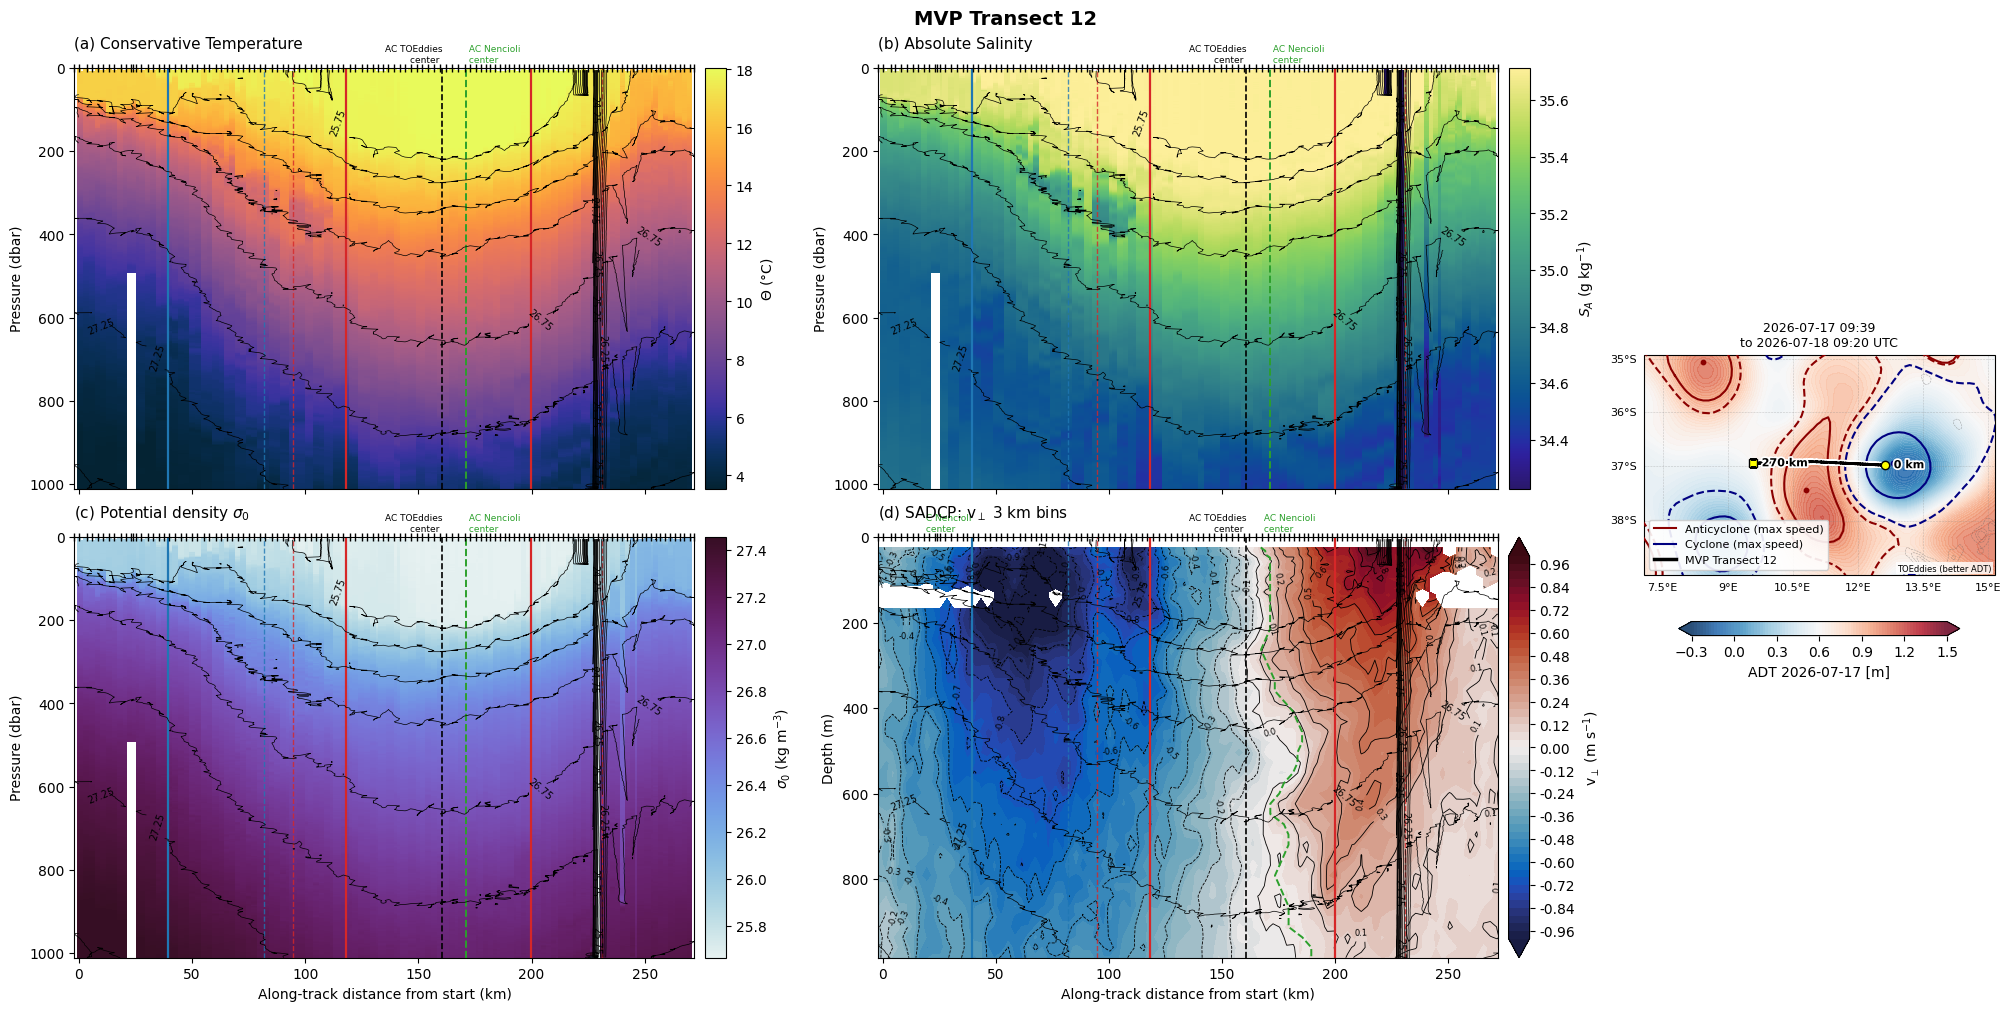

In [11]:
# ---------------- map background for the combined figure ----------------
out_dir = str(BASE / "figures/mvp") + f"/{transect}/"

date = pd.to_datetime(mvp_trans["TIME"]).median().strftime("%Y-%m-%d")
date_compact = date.replace("-", "")
ssh = load_satellite(DIR_SSH / [f for f in daily_ssh_files if date in f or date_compact in f][0])
eddy_files, eddy_source = get_eddy_files(date_compact, date)

edds = eddies_on_transect(eddy_files, mvp_trans["LON (°E)"].values, mvp_trans["LAT (°N)"].values)
print("eddies crossed:", [("C" if e["cyc"] else "AC") + f" ({e['dist_km']:.0f} km from track)" for e in edds])

# ---------------- SADCP for zeta (PV) ----------------
ds = sadcp_tr                      # ADCP subset for this transect (sadcp_mvp is ~1 GB, not needed)
zdim = ds["depth"].dims[0]
u = ds["UVEL_ADCP_CORTIDE"].transpose("time", zdim).values
v = ds["VVEL_ADCP_CORTIDE"].transpose("time", zdim).values
pg = ds["PGOOD_ADCP"].transpose("time", zdim).values

u[pg < 50] = np.nan
v[pg < 50] = np.nan

args = [ssh, eddy_files, transect, eddy_source, adt_ticks, date, levels]
# ---------------- map + Theta / S_A / sigma0 ----------------
sec, fig, axs = process_transect(
    mvp_trans, adcp=sadcp_mvp_processed, cast_col="CAST",
    map_draw=draw_background,      # map_extent=extent  -> whole region instead of zoom
    map_args = args,
    title=f"MVP {transect}",
    eddy=edds,
    savepath=out_dir + f"{transect}_sections_hydro_adcp.png",
    flip_x = False)
plt.show()

zeta/f, upper 300 m: min -0.42 (anticyclonic), max 0.91 (cyclonic)


/var/folders/lg/5krm8xnn5xv0smms_psmknp40000gn/T/ipykernel_27762/3547459185.py:63: UserWarning: The following kwargs were not used by contour: 'shading'
  pc = ax.contourf(xg, z_a, ro.T, cmap="RdBu", levels=levels, shading="nearest", extend='both')


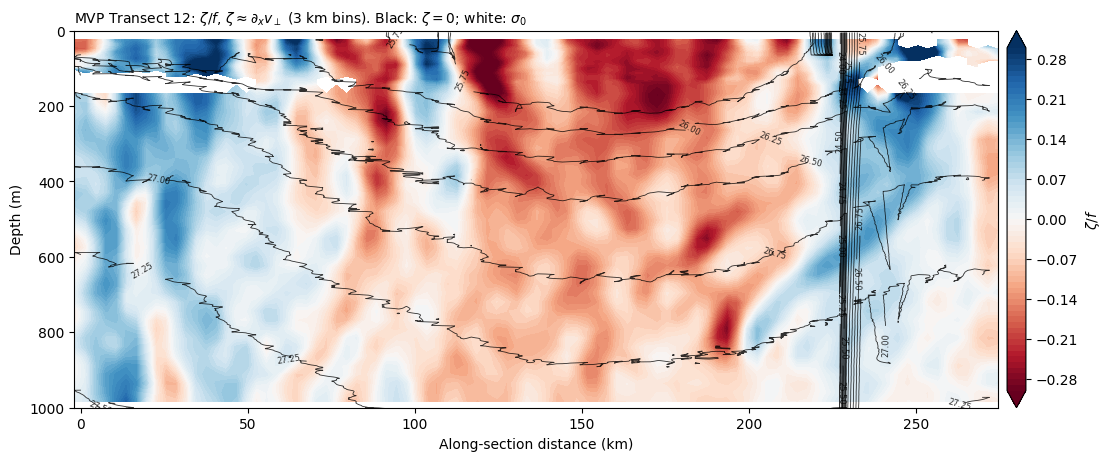

In [12]:
# ---------------- normalized relative vorticity zeta/f from SADCP ----------------
from scipy.ndimage import uniform_filter1d
import cmocean

DX_KM      = DS_KM   # along-track bin (km); same 3 km bins as panel (d)
SMOOTH_X   = 3       # running mean over this many bins along x before differentiating (1 = none)
SMOOTH_Z   = 3       # running mean over this many SADCP levels in depth (1 = none)
PMV_FACTOR = 1       # 1 = Rudnick (Barabinot 2025), 2 = poor man's vorticity
RO_LIM     = 0.3    # colour limit for zeta/f; None = 98th percentile of |zeta/f|
ZMAX       = 1000    # m, bottom of the plot
FLIP_X     = True    # same orientation as the section figure above


def nan_smooth(a, size, axis):
    """Running mean that ignores NaNs (NaNs stay NaN)."""
    if size <= 1:
        return a
    w = np.isfinite(a).astype(float)
    num = uniform_filter1d(np.where(w > 0, a, 0.0), size, axis=axis, mode="nearest")
    den = uniform_filter1d(w, size, axis=axis, mode="nearest")
    out = num / np.where(den > 0, den, np.nan)
    out[w == 0] = np.nan
    return out


ad = sadcp_mvp_processed                      # OS150 above 150 m + OS38 below, 10-min profiles
z_a = np.asarray(ad["z"], float)

# 1) cross-track velocity on the same x axis as the MVP section (origin = first cast,
#    +x = first -> last cast). v_perp > 0 to the LEFT of +x, so (x, v_perp) is right-handed
#    and zeta = d v_perp / dx has the usual sign (zeta > 0 counter-clockwise).
s_m, _ = along_track_x(np.asarray(ad["lon"], float), np.asarray(ad["lat"], float),
                       sec["lon"][0], sec["lat"][0], sec["xdir"])
s = s_m / 1e3
ex = sec["xdir"]
v_perp = -ad["u"] * ex[1] + ad["v"] * ex[0]

# 2) bin along x, fill small vertical gaps (OS150/OS38 seam), smooth
edges = np.arange(np.floor(np.nanmin(s)), np.ceil(np.nanmax(s)) + DX_KM, DX_KM)
xg, V, cnt = bin_columns(s, v_perp, edges)
_, LATb, _ = bin_columns(s, np.asarray(ad["lat"], float)[:, None], edges)
V = fill_z_gaps(V, z_a)
V = nan_smooth(nan_smooth(V, SMOOTH_X, axis=0), SMOOTH_Z, axis=1)

# 3) zeta = d v_perp / dx (centred differences), and f at each bin's latitude
zeta = PMV_FACTOR * np.gradient(V, xg * 1e3, axis=0)            # s^-1, shape (nx, nz)
lat_b = LATb[:, 0]
lat_b = np.where(np.isfinite(lat_b), lat_b, np.nanmean(lat_b))
f_b = 2 * OMEGA * np.sin(np.deg2rad(lat_b))                       # < 0 in the south
ro = zeta / f_b[:, None]                                          # zeta / f

# zeta/f < 0 = anticyclonic in both hemispheres (Agulhas rings: zeta > 0, f < 0)
vort = dict(x=xg, z=z_a, v_perp=V, zeta=zeta, f=f_b, ro=ro, n_fixes=cnt)

top = z_a <= 300
print(f"zeta/f, upper 300 m: min {np.nanmin(ro[:, top]):.2f} (anticyclonic), "
      f"max {np.nanmax(ro[:, top]):.2f} (cyclonic)")

# 4) figure: zeta/f, zeta = 0 contour (eddy boundary, Barabinot 2025), sigma0, v_perp
lim = RO_LIM or max(0.1, np.round(np.nanpercentile(np.abs(ro), 98), 1))
fig, ax = plt.subplots(figsize=(11, 4.5), constrained_layout=True)
levels = np.linspace(-lim, lim, int(RO_LIM * 200) + 1)
pc = ax.contourf(xg, z_a, ro.T, cmap="RdBu", levels=levels, shading="nearest", extend='both')
# ax.contour(xg, z_a, zeta.T, levels=[0], colors="k", linewidths=1.2)
# cs = ax.contour(xg, z_a, V.T, levels=np.arange(-1.5, 1.51, 0.2), colors="gray",
#                 linewidths=0.5, linestyles="solid")
# ax.clabel(cs, fmt="%.1f", fontsize=6)
sig_lev = np.arange(np.floor(np.nanmin(sec["sig0"]) * 4) / 4, np.nanmax(sec["sig0"]), 0.25)
cs2 = ax.contour(sec["x"] / 1e3, sec["p"], sec["sig0"], levels=sig_lev,      # p (dbar) ~ z (m)
                 colors="black", linewidths=0.6, alpha=0.8)
ax.clabel(cs2, fmt="%.2f", fontsize=6)
ax.set_ylim(ZMAX, 0)
FLIP_X = False
if FLIP_X:
    ax.invert_xaxis()
ax.set_xlabel("Along-section distance (km)")
ax.set_ylabel("Depth (m)")
cb = fig.colorbar(pc, ax=ax, pad=0.01, extend="both")
cb.set_label(r"$\zeta / f$")
ax.set_title(rf"MVP {transect}: $\zeta/f$, $\zeta \approx {'2' if PMV_FACTOR == 2 else ''}"
             rf"\partial_x v_\perp$ ({DX_KM:.0f} km bins). Black: $\zeta=0$; " # grey: $v_\perp$ (m s$^{{-1}}$)
             r"white: $\sigma_0$", loc="left", fontsize=10)
fig.savefig(out_dir + f"{transect}_zeta_over_f.png", dpi=300)
plt.show()